# Passau MedCo · Task 2: Predicting Employee Attrition

**Can we use a model to reliably predict employee attrition?**

Train a regularized logistic regression on the fictional IBM HR data and evaluate how well it ranks and flags employees who left.

## 1. Which algorithm did we choose, and why?

We chose **L2-regularized logistic regression** for this binary classification task. It combines signals across employee features, returns a score for the positive class, and represents each feature through coefficients on the log-odds scale. Regularization limits how strongly individual features can influence the score. We use average precision (AP) for model tuning because attrition is the minority class.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

## 2. How did we split the data?

We use one row per employee from [the project CSV](data/employee-attrition.csv). A fixed, stratified **80/20 split** with seed 42 preserves the share of employees who left in each partition. Training and threshold selection use only the training partition. The project EDA used the full snapshot, and the test split was examined during development, so the test results are a benchmark for this project dataset.

A 90/10 split would leave about 24 positive cases for testing, roughly half the number in the 80/20 split. The training-size check below compares smaller and larger fitting sets against the same validation employees. The CSV is a snapshot, so validating predictions for a future period would require dated data.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
# The CSV pads some headers and text values with spaces. Clean both before using labels such as "Yes".
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip()

random_seed = 42
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].notna().all() and employees["EmployeeNumber"].is_unique
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

# X holds the features. The employee ID was useful for checking uniqueness, and Attrition is the label.
X = employees.drop(columns=["EmployeeNumber", "Attrition"])
y = employees["Attrition"].eq("Yes").astype(int)

# Stratification keeps the share of employees who left similar in both partitions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=random_seed
)
# Find constant features using training rows and remove the same columns from both partitions.
constant_columns = X_train.columns[X_train.nunique(dropna=False).eq(1)]
X_train = X_train.drop(columns=constant_columns)
X_test = X_test.drop(columns=constant_columns)

display(pd.DataFrame({
    "Employees": [len(y_train), len(y_test)],
    "Employees who left": [y_train.sum(), y_test.sum()],
}, index=["Train", "Test"]))

,Employees,Employees who left
Train,1176,190
Test,294,47


## 3. Which settings did we use, and why?

The pipeline scales continuous inputs and one-hot encodes categorical inputs. We also one-hot encode job level and stock option level because their EDA patterns vary unevenly across codes. The income ratio compares each salary with the median at the same job level. That median is fitted within each training fold.

Four inner folds choose the regularization strength `C` and the transformation of the three skewed features. Five outer folds estimate performance on validation rows. The LBFGS solver uses the L2 penalty and equal class weights, with up to 1,000 iterations to converge.

In [3]:
class IncomeWithinJobLevel(TransformerMixin, BaseEstimator):
    """Compare monthly income with the median for the employee's job level."""

    def fit(self, X, y=None):
        # This runs inside the pipeline, so the medians come from the current training fold.
        self.level_medians_ = X.groupby("JobLevel")["MonthlyIncome"].median()
        self.overall_median_ = X["MonthlyIncome"].median()
        return self

    def transform(self, X):
        # A ratio of 1.0 means income equals the median for that job level.
        # Use the training-wide median if prediction data contains a new job level.
        level_median = X["JobLevel"].map(self.level_medians_).fillna(self.overall_median_)
        return (X["MonthlyIncome"] / level_median).to_frame("MonthlyIncomeRelativeToJobLevel")

    def get_feature_names_out(self, input_features=None):
        return ["MonthlyIncomeRelativeToJobLevel"]


categorical_features = X_train.select_dtypes(include="str").columns.tolist()
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
skewed_features = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
# EDA showed uneven attrition rates across these codes. One-hot encoding lets the model learn
# a separate effect for each level.
categorical_levels = ["JobLevel", "StockOptionLevel"]

linear_numeric = [
    column for column in numeric_features
    if column not in skewed_features and column not in categorical_levels
]
# Scaling makes regularization comparable across numeric features measured in different units.
# The search also tests a power transform for the three skewed numeric features.
linear_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), linear_numeric),
    ("skewed", StandardScaler(), skewed_features),
    ("relative_income", make_pipeline(IncomeWithinJobLevel(), StandardScaler()), ["JobLevel", "MonthlyIncome"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), [*categorical_features, *categorical_levels]),
])


# Tune regularization and the transformation of skewed inputs using the training folds.
inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=random_seed)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)
logistic_search = GridSearchCV(
    make_pipeline(linear_preprocessing, LogisticRegression(max_iter=1000)),
    {
        # Smaller C applies a stronger penalty to the coefficients.
        "logisticregression__C": [0.03, 0.1, 0.3, 1.0, 3.0],
        "columntransformer__skewed": [StandardScaler(), PowerTransformer()],
    },
    scoring="average_precision",
    cv=inner_cv,
    n_jobs=4,
    error_score="raise",
)

### Check how the training size affects performance

Within each outer fold, fit the pipeline on 70%, 85%, and 100% of the available fitting rows. The percentages refer to the outer fold's training pool. Each size is tuned separately and scored on the same outer validation rows. This shows sensitivity to training size while keeping the final test set out of the comparison.

Mean validation AP rose from **0.659** at about 658 fitting rows to **0.693** at about 941. The larger fitting sets helped over this range. The 80/20 split combines 1,176 rows for the final fit with 47 positive cases for estimating test recall.

In [4]:
training_fractions = (0.70, 0.85, 1.0)
out_of_fold_scores = pd.Series(index=X_train.index, dtype=float)
validation_rows = []

with parallel_config(backend="loky", inner_max_num_threads=1):
    for fold, (fit_indices, validation_indices) in enumerate(outer_cv.split(X_train, y_train), start=1):
        X_validation = X_train.iloc[validation_indices]
        y_validation = y_train.iloc[validation_indices]

        for fraction in training_fractions:
            # Keep the validation rows fixed. Change only the number of fitting rows.
            train_indices = fit_indices
            if fraction < 1:
                train_indices, _ = train_test_split(
                    fit_indices,
                    train_size=fraction,
                    stratify=y_train.iloc[fit_indices],
                    random_state=random_seed + fold,
                )

            # Each sample size gets its own inner search and fitted preprocessing.
            search = clone(logistic_search).fit(X_train.iloc[train_indices], y_train.iloc[train_indices])
            scores = search.predict_proba(X_validation)[:, 1]
            if fraction == 1.0:
                # Save one prediction per training employee for threshold selection.
                out_of_fold_scores.loc[X_validation.index] = scores

            validation_rows.append({
                "Training fraction": f"{fraction:.0%}",
                "Rows fitted": len(train_indices),
                "AP": average_precision_score(y_validation, scores),
            })

size_results = (
    pd.DataFrame(validation_rows)
    .groupby("Training fraction", sort=False)
    .agg(**{
        "Mean rows fitted": ("Rows fitted", "mean"),
        "Mean validation AP": ("AP", "mean"),
        "AP fold SD": ("AP", "std"),
    })
)
size_results["Mean rows fitted"] = size_results["Mean rows fitted"].round().astype(int)
display(size_results.round(3))

,Mean rows fitted,Mean validation AP,AP fold SD
Training fraction,,,
70%,658,0.659,0.043
85%,799,0.685,0.060
100%,941,0.693,0.070


### Choose decision thresholds and train on the full training split

The full-size outer-fold predictions give one score per training employee. Use those scores to choose an F1 threshold, a recall-focused F2 threshold, and the highest threshold that reaches at least 50% recall on these validation predictions. Then run the hyperparameter search and refit on all training rows.

The full training search chose **C = 0.3** and **PowerTransformer** for monthly income, years at the company, and total working years. Those settings produced the highest mean inner-fold AP.

In [5]:
def choose_thresholds(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    # The curve has one extra endpoint without a matching cutoff.
    precision, recall = precision[:-1], recall[:-1]
    choices = {}
    # F1 balances precision and recall, while F2 gives recall more weight.
    for beta in (1, 2):
        beta_squared = beta ** 2
        denominator = (beta_squared * precision + recall).clip(min=1e-12)
        f_beta = (1 + beta_squared) * precision * recall / denominator
        choices[f"F{beta}"] = float(thresholds[f_beta.argmax()])

    recall_target = 0.50
    choices[f"{recall_target:.0%} CV recall"] = float(thresholds[recall >= recall_target][-1])
    return choices

# Choose cutoffs from outer-fold scores, then tune and fit the model on all training rows.
decision_thresholds = choose_thresholds(y_train, out_of_fold_scores)
with parallel_config(backend="loky", inner_max_num_threads=1):
    final_search = clone(logistic_search).fit(X_train, y_train)

selected_model = final_search.best_estimator_
decision_threshold = decision_thresholds["F1"]
print("Selected hyperparameters:")
for parameter, value in final_search.best_params_.items():
    print(f"  {parameter}: {value}")

Selected hyperparameters:
  columntransformer__skewed: PowerTransformer()
  logisticregression__C: 0.3


## 4. How well does the classifier perform?

Use the 294 test employees to evaluate the fitted pipeline. AP assesses the ranking across all cutoffs. **Precision** is the share of alerts that correspond to employees who left. **Recall** is the share of employees who left that the model identifies.

In [6]:
# Reuse the same test scores for all cutoffs. Scores determine the ranking and each cutoff defines the labels.
test_scores = selected_model.predict_proba(X_test)[:, 1]
test_predictions = test_scores >= decision_threshold
test_ap = average_precision_score(y_test, test_scores)
print(f"Test average precision: {test_ap:.3f} (constant-score reference: {y_test.mean():.3f})")

test_rows = []
for threshold_name, threshold in decision_thresholds.items():
    # A positive prediction with label 1 is a hit. A positive prediction with label 0 is a false alarm.
    predictions = test_scores >= threshold
    test_rows.append({
        "Decision rule": threshold_name,
        "Cutoff": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "F2": fbeta_score(y_test, predictions, beta=2, zero_division=0),
        "Employees who left detected": int((predictions & y_test.eq(1)).sum()),
        "False alarms": int((predictions & y_test.eq(0)).sum()),
    })

test_metrics = pd.DataFrame(test_rows).set_index("Decision rule")
display(test_metrics.round(3))

Test average precision: 0.654 (constant-score reference: 0.160)


,Cutoff,Precision,Recall,F1,F2,Employees who left detected,False alarms
Decision rule,,,,,,,
F1,0.392,0.639,0.489,0.554,0.513,23,13
F2,0.273,0.517,0.660,0.579,0.625,31,29
50% CV recall,0.468,0.808,0.447,0.575,0.491,21,5


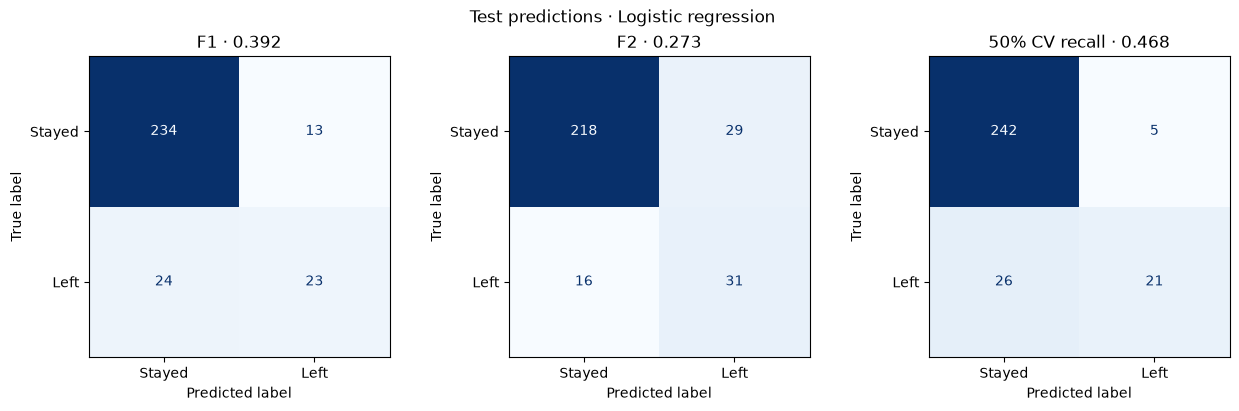

In [7]:
%matplotlib inline

fig, axes = plt.subplots(1, len(decision_thresholds), figsize=(12.6, 4), layout="constrained")
for ax, (threshold_name, threshold) in zip(axes, decision_thresholds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_scores >= threshold, labels=[0, 1], display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{threshold_name} · {threshold:.3f}")
fig.suptitle("Test predictions · Logistic regression")
plt.show()

### What does this mean for Passau MedCo?

The model shows useful ranking signal on this fictional dataset. Test **AP was 0.654**, compared with **0.160** for a constant score.

- **Precision-focused cutoff.** 21 of 47 employees who left were detected and five alerts were false. Precision was 80.8% and recall was 44.7%.
- **Recall-focused F2 cutoff.** 31 of 47 employees who left were detected and 29 alerts were false. Recall was 66.0% and precision was 51.7%.

This is suitable as a **proof of concept** for attrition classification. Reliable use for individual predictions would require validation on a new, later workforce sample and a decision threshold tied to the costs of missed cases and false alerts.